---
title: "Dielectrics and Polarization — Level 2"
short_title: "05 Dielectrics"
numbering:
  heading_2: true
  equation: true
---

# Dielectrics and Polarization

:::{seealso} Math for this topic
- [E-M1: Vector calculus for fields](../math/01-vector-calculus-fields.ipynb)
- [E-M2: Separation of variables and orthogonal functions](../math/02-separation-of-variables.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | Tipler & Mosca, ch. 24 | Capacitor with a dielectric slab |
| **2** | **Griffiths, ch. 4** | **Bound charge, the D field, linear dielectrics** |
| 3 | Jackson, ch. 4 | Boundary-value problems with dielectric interfaces, molecular models |

The new skill at this level: describing matter by a polarization field, and separating the charges you control from the ones the material supplies

Math for this topic: E-M1 (vector calculus) and E-M2 (separation of variables for the sphere).
:::

Workbook example ladder: slab-filled capacitor → dielectric sphere in a uniform field → the Clausius–Mossotti relation. Exercises have separate hint and answer dropdowns.

::::{admonition} Pre-test: can you skip this notebook?
:class: dropdown

Work these without looking at the notes. Each problem names the section it tests. If **every part** is right, skip ahead to [Magnetostatics](06-magnetostatics.ipynb). If you miss a part, study just the section it names and try that problem again.

1. **How Matter Responds to a Field**

   Name the two ways a material polarizes. Which one dominates for water and which for argon? Which one depends on temperature, and how?

2. **Bound Charge**

   (a) A long cylinder of radius $R$ has radial polarization $\vec{P} = ks\,\hat{s}$. Find $\rho_b$ and $\sigma_b$, and check that the total bound charge per unit length is zero.

   (b) What is the field inside a uniformly polarized sphere?

3. **The Displacement Field $\vec{D}$**

   (a) A point charge $q$ sits at the center of a dielectric shell ($a < r < b$, constant $\epsilon_r$). Find $\vec{D}$ everywhere and $\vec{E}$ inside the shell.

   (b) A uniform field $E_0$ in vacuum meets the flat face of a large dielectric slab head-on. What is $E$ inside the slab? Which boundary condition did you use?

   (c) Why can $\vec{D}$ have a curl even in electrostatics?

4. **Linear Dielectrics**

   (a) A capacitor is filled with dielectric $\epsilon_r$. By what factor does $C$ change?

   (b) A dielectric sphere with $\epsilon_r = 4$ sits in a uniform field $E_0$. Find the field inside.

5. **From Atoms to $\epsilon_r$: Clausius–Mossotti**

   A gas with number density $N = 2.7\times10^{25}\ \text{m}^{-3}$ has $\epsilon_r = 1.0006$. Find the atomic polarizability $\alpha$, and $\alpha/(4\pi\epsilon_0)$ in m³.

6. **Energy and Forces**

   A dielectric slab is partly inserted into a capacitor. Is it pulled in or pushed out if the capacitor (a) is isolated with fixed $Q$, or (b) stays connected to a battery at fixed $V$? Explain each using energy.

:::{dropdown} Answers
1. Induced (stretched) atomic dipoles and the alignment of permanent dipoles. Water is dominated by alignment, argon by induced dipoles. Alignment depends on temperature roughly as $1/T$, because thermal motion scrambles it.

2. (a) $\rho_b = -\nabla\cdot\vec{P} = -\dfrac1s\dfrac{d}{ds}(ks^2) = -2k$ and $\sigma_b = \vec{P}\cdot\hat{s} = kR$. Per unit length, $-2k\pi R^2 + kR\cdot2\pi R = 0$.

   (b) $\vec{E} = -\vec{P}/(3\epsilon_0)$, uniform.

3. (a) $\vec{D} = \dfrac{q}{4\pi r^2}\hat{r}$ everywhere, and $\vec{E} = \dfrac{q}{4\pi\epsilon_0\epsilon_rr^2}\hat{r}$ in the shell.

   (b) $E_0/\epsilon_r$. With no free surface charge, $D_\perp$ is continuous.

   (c) $\nabla\times\vec{D} = \nabla\times\vec{P}$, which need not be zero (for example at the edges of a finite polarized object).

4. (a) It is multiplied by $\epsilon_r$.

   (b) $3E_0/(\epsilon_r + 2) = E_0/2$.

5. $\alpha \approx \epsilon_0(\epsilon_r - 1)/N \approx 2.0\times10^{-40}$ C m²/V, and $\alpha/(4\pi\epsilon_0) \approx 1.8\times10^{-30}$ m³.

6. Pulled in, in both cases. (a) $W = Q^2/2C$ falls as $C$ grows. (b) $\tfrac12CV^2$ rises, but the battery supplies twice that increase, so the total energy of capacitor plus battery still falls as the slab moves in.
:::
::::

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad, dblquad

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
eps0 = 8.854e-12          # F/m
mu0 = 4e-7 * np.pi        # H/m (to 10 significant figures)
c = 2.998e8               # m/s
k_e = 1 / (4 * np.pi * eps0)

## How Matter Responds to a Field

In an insulator, charges cannot flow, but they can shift slightly. Two mechanisms produce microscopic dipoles:

- **Induced dipoles.** The field pulls an atom's electron cloud one way and its nucleus the other, giving $\vec{p} = \alpha\vec{E}$, where $\alpha$ is the atomic **polarizability**.
- **Orientation.** Polar molecules (water, ammonia) already have dipoles. The field tends to align them (torque $\vec{p}\times\vec{E}$), against thermal agitation.

Either way, the material ends up with a dipole moment per unit volume, the **polarization** $\vec{P}$.

## Bound Charge

The potential of a polarized object is the sum of the potentials of all its little dipoles:

$$
V(\vec{r}) = \frac{1}{4\pi\epsilon_0}\int\frac{\vec{P}(\vec{r}')\cdot\hat{\mathscr{r}}}{\mathscr{r}^2}\,d\tau' .
$$

Using $\hat{\mathscr{r}}/\mathscr{r}^2 = \nabla'(1/\mathscr{r})$, a product rule (E-M1), and the divergence theorem, this becomes

$$
V = \frac{1}{4\pi\epsilon_0}\oint\frac{\sigma_b}{\mathscr{r}}\,da' + \frac{1}{4\pi\epsilon_0}\int\frac{\rho_b}{\mathscr{r}}\,d\tau', \qquad
\sigma_b = \vec{P}\cdot\hat{n}, \qquad \rho_b = -\nabla\cdot\vec{P} .
$$ (eq-bound-charge)

A polarized object produces exactly the field of a surface charge $\sigma_b$ and a volume charge $\rho_b$. These **bound charges** are real accumulations of charge: at a surface, the ends of the aligned dipoles do not cancel; inside, a nonuniform polarization leaves a net imbalance.

::::{prf:example} A uniformly polarized sphere
:label: ex-polarized-sphere

A sphere of radius $R$ has uniform polarization $\vec{P} = P\hat{z}$. Find the field inside.

:::{dropdown} Solution
$\rho_b = -\nabla\cdot\vec{P} = 0$, and $\sigma_b = \vec{P}\cdot\hat{r} = P\cos\theta$. That surface charge is exactly the one induced on a conducting sphere in a uniform field (topic 3), whose potential is known. Solving Laplace's equation inside and outside with the jump condition (E-M2) gives

$$
V_{\text{in}} = \frac{P}{3\epsilon_0}r\cos\theta = \frac{Pz}{3\epsilon_0}, \qquad \vec{E}_{\text{in}} = -\frac{\vec{P}}{3\epsilon_0} .
$$

The field inside is uniform and opposite to $\vec{P}$ (it is called the **depolarizing** field). Outside, the field is exactly that of a point dipole $\vec{p} = \tfrac43\pi R^3\vec{P}$, the total dipole moment.
:::
::::

## The Displacement Field $\vec{D}$

Inside a material, split the charge into **free** charge $\rho_f$ (what you put there: electrons on a capacitor plate, ions you deposit) and **bound** charge $\rho_b = -\nabla\cdot\vec{P}$. Gauss's law, $\epsilon_0\nabla\cdot\vec{E} = \rho_f + \rho_b$, becomes

$$
\nabla\cdot\vec{D} = \rho_f, \qquad \vec{D}\equiv\epsilon_0\vec{E} + \vec{P} ,
$$ (eq-d-field)

or in integral form $\oint\vec{D}\cdot d\vec{a} = Q_{f,\text{enc}}$. The point is that $\vec{D}$ depends only on charge you control, so in symmetric situations it can be found with Gauss's law before knowing anything about the material.

:::{warning} $\vec{D}$ is not determined by $\rho_f$ alone
Unlike $\vec{E}$, $\vec{D}$ can have a curl: $\nabla\times\vec{D} = \nabla\times\vec{P}$, which need not vanish. So there is no "Coulomb's law for $\vec{D}$". The Gauss's-law shortcut for $\vec{D}$ works only when the symmetry also makes the curl vanish (spherical, cylindrical, planar setups with the material respecting that symmetry).
:::

### Boundary conditions

At an interface carrying free surface charge $\sigma_f$:

$$
D^{\text{above}}_\perp - D^{\text{below}}_\perp = \sigma_f, \qquad \vec{E}_\parallel^{\text{above}} = \vec{E}_\parallel^{\text{below}} .
$$

## Linear Dielectrics

For most materials in ordinary fields, the polarization is proportional to the field:

$$
\vec{P} = \epsilon_0\chi_e\vec{E}, \qquad \vec{D} = \epsilon\vec{E}, \qquad \epsilon = \epsilon_0(1 + \chi_e) = \epsilon_0\epsilon_r .
$$

$\chi_e$ is the **electric susceptibility** and $\epsilon_r$ the **dielectric constant**: about $1.0006$ for air, $2$–$4$ for plastics and glass, $80$ for water.

When a linear dielectric fills **all** the space where the field is, the field is reduced by $\epsilon_r$ everywhere compared with vacuum, and capacitances grow by $\epsilon_r$. When it fills only part, the bound charges on its surfaces reshape the field, and the problem must be solved with the boundary conditions.

::::{prf:example} A dielectric sphere in a uniform field
:label: ex-dielectric-sphere

A sphere of radius $R$ and dielectric constant $\epsilon_r$ is placed in a uniform field $\vec{E}_0$. Find $\vec{E}$ inside.

:::{dropdown} Solution
Try the forms from E-M2 with only $\ell = 1$ terms:

$$
V_{\text{in}} = Ar\cos\theta, \qquad V_{\text{out}} = \left(-E_0r + \frac{B}{r^2}\right)\cos\theta .
$$

The conditions at $r = R$ are continuity of $V$ (tangential $\vec{E}$) and of $\epsilon\,\partial V/\partial r$ (normal $\vec{D}$, no free charge):

$$
AR = -E_0R + \frac{B}{R^2}, \qquad \epsilon_rA = -E_0 - \frac{2B}{R^3} .
$$

Solving: $A = -\dfrac{3E_0}{\epsilon_r + 2}$, so

$$
\vec{E}_{\text{in}} = \frac{3}{\epsilon_r + 2}\,\vec{E}_0 ,
$$

a **uniform** field weaker than $\vec{E}_0$. As $\epsilon_r\to\infty$ it goes to zero, the conductor limit.
:::
::::

In [2]:
A, B = sp.symbols("A B")                      # A turns out negative, so no sign assumptions here
E0, R, er = sp.symbols("E_0 R epsilon_r", positive=True)
sol = sp.solve([sp.Eq(A * R, -E0 * R + B / R**2), sp.Eq(er * A, -E0 - 2 * B / R**3)], [A, B], dict=True)[0]
display(Math("A = " + sp.latex(sp.simplify(sol[A])) + r",\qquad B = " + sp.latex(sp.simplify(sol[B]))))
display(Math(r"\frac{E_{\text{inside}}}{E_0} = " + sp.latex(sp.simplify(-sol[A] / E0))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

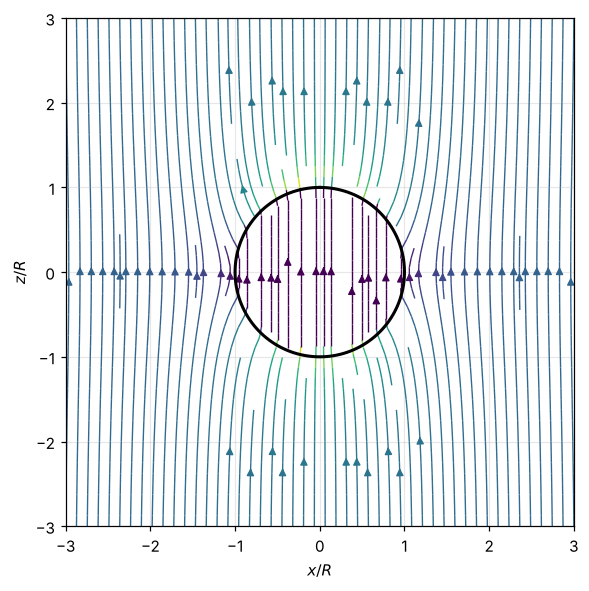

In [3]:
#| label: fig-dielectric-sphere
#| caption: E-field lines around and inside a dielectric sphere (ε_r = 4) in a uniform field. Inside, the field is uniform and reduced to 3/(ε_r + 2) = 1/2 of E₀; outside, the bound surface charge adds a dipole field that bends lines toward the sphere.
er_, R_ = 4.0, 1.0
x = np.linspace(-3, 3, 320); z = np.linspace(-3, 3, 320)
X, Z = np.meshgrid(x, z)
r = np.hypot(X, Z) + 1e-12
Bc = (er_ - 1) / (er_ + 2) * R_**3          # B / E0
Ex = 3 * Bc * X * Z / r**5
Ez = 1 + Bc * (3 * Z**2 - r**2) / r**5
inside = r < R_
Ex[inside] = 0.0; Ez[inside] = 3 / (er_ + 2)
fig, ax = plt.subplots(figsize=(6, 6))
ax.streamplot(X, Z, Ex, Ez, density=1.6, color=np.hypot(Ex, Ez), cmap="viridis", linewidth=0.9)
th = np.linspace(0, 2 * np.pi, 300)
ax.plot(R_ * np.sin(th), R_ * np.cos(th), "k", lw=2)
ax.set_aspect("equal"); ax.set_xlabel("$x/R$"); ax.set_ylabel("$z/R$"); plt.show()

### Exercises

1. A parallel-plate capacitor (area $A$, gap $d$) is half filled with a slab of dielectric constant $\epsilon_r$: the slab has thickness $d/2$ and covers the whole area. Find the capacitance.
2. A point charge $q$ is embedded at the center of a large ball of linear dielectric. Find $\vec{D}$, $\vec{E}$ and the bound charge right around $q$.
3. Show that in a linear dielectric with no free charge, $\rho_b = 0$, so all bound charge is on surfaces.

:::{dropdown} Hints
1. $D$ is the same in both layers (normal component, no free charge between); the voltages add.
2. Use Gauss's law for $\vec{D}$; then $\vec{E} = \vec{D}/\epsilon$. The bound charge near $q$ screens it.
3. $\rho_b = -\nabla\cdot\vec{P} = -\chi_e\epsilon_0\nabla\cdot\vec{E}$, and $\nabla\cdot\vec{D} = 0$.
:::

:::{dropdown} Answers
1. $C = \dfrac{2\epsilon_0A}{d}\dfrac{\epsilon_r}{\epsilon_r + 1}$ (two capacitors in series).
2. $\vec{D} = \dfrac{q}{4\pi r^2}\hat{r}$, $\vec{E} = \dfrac{q}{4\pi\epsilon r^2}\hat{r}$: as if the charge were $q/\epsilon_r$. A bound charge $-q(1 - 1/\epsilon_r)$ clusters around $q$, partly screening it.
3. $\nabla\cdot\vec{D} = \epsilon\nabla\cdot\vec{E} = 0$ gives $\nabla\cdot\vec{E} = 0$, so $\rho_b = 0$.
:::

## From Atoms to $\epsilon_r$: Clausius–Mossotti

Each atom in a dense material feels not the average field $\vec{E}$ but the field of everything **except itself**. Modeling the atom's surroundings as a uniformly polarized medium with a small spherical hole around the atom, the hole's field adds $\vec{P}/(3\epsilon_0)$ (the opposite of the polarized-sphere result). Then $\vec{P} = N\alpha\left(\vec{E} + \vec{P}/3\epsilon_0\right)$ with $N$ atoms per volume, which gives

$$
\frac{\epsilon_r - 1}{\epsilon_r + 2} = \frac{N\alpha}{3\epsilon_0} .
$$

This links a macroscopic constant to an atomic property, and it works well for gases and nonpolar liquids. It is the Level 3 rung of this topic.

## Energy and Forces

In a linear dielectric, the energy of a configuration of free charges is $W = \tfrac12\int\vec{D}\cdot\vec{E}\,d\tau$. For a capacitor held at fixed charge, inserting a dielectric lowers the energy, so the dielectric is **pulled in** by the fringing field at the edge of the plates, even though inside the plates the field is perpendicular to the motion.

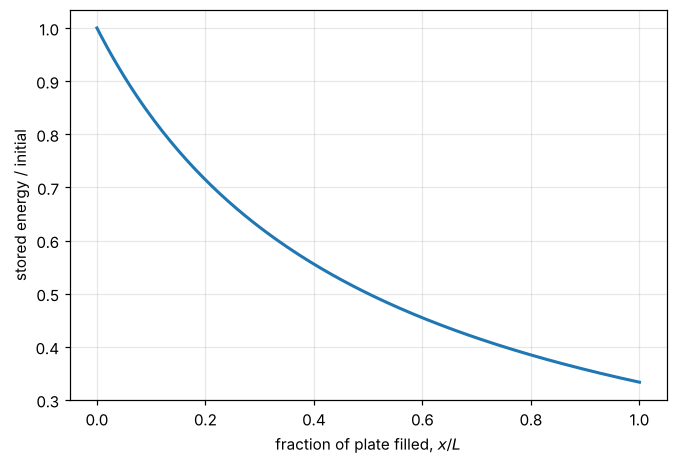

force at x = 0: 1.118e-07 N; at x = L/2: 2.810e-08 N  (pulls the slab in)


In [4]:
#| label: fig-slab-force
#| caption: Energy of a charged, isolated capacitor (fixed Q) as a dielectric slab (ε_r = 3) slides in a distance x. The energy falls as the slab enters, so the force F = −dW/dx pulls it in; it is constant because C grows linearly with x.
w_, L_, d_, er_ = 1.0, 1.0, 0.01, 3.0
x = np.linspace(0, L_, 200)
C = eps0 * w_ / d_ * (er_ * x + (L_ - x))
Q = 1e-8
W = Q**2 / (2 * C)
fig, ax = plt.subplots()
ax.plot(x / L_, W / W[0], lw=2)
ax.set_xlabel("fraction of plate filled, $x/L$"); ax.set_ylabel("stored energy / initial")
plt.show()
F = -np.gradient(W, x)
print(f"force at x = 0: {F[0]:.3e} N; at x = L/2: {F[100]:.3e} N  (pulls the slab in)")

## Summary

- Matter polarizes by stretching atoms and aligning polar molecules; $\vec{P}$ is the dipole moment per volume.
- A polarized object acts like bound charges $\sigma_b = \vec{P}\cdot\hat{n}$ and $\rho_b = -\nabla\cdot\vec{P}$; a uniformly polarized sphere has $\vec{E}_{\text{in}} = -\vec{P}/3\epsilon_0$.
- $\vec{D} = \epsilon_0\vec{E} + \vec{P}$ obeys $\nabla\cdot\vec{D} = \rho_f$, but may have a curl.
- Linear dielectrics: $\vec{D} = \epsilon\vec{E}$. A dielectric sphere in a uniform field has a uniform interior field $3\vec{E}_0/(\epsilon_r + 2)$.
- Clausius–Mossotti connects $\epsilon_r$ to atomic polarizability; dielectrics are drawn into capacitors.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.